# **Cardiovascular_disease_prediction**



Heart disease, also known as cardiovascular disease, is one of the most serious illnesses in both India and the rest of the globe. According to estimates, cardiac illnesses account for **28.1% of fatalities**. More than 17.6 million fatalities were caused by it in 2016 alone. Therefore, a system that can predict with precision and dependability is required for the appropriate and prompt diagnosis and treatment of such diseases.

**Objectives (as per project brief):**
1. Perform data pre-processing operations.
2. Draw all possible plots for data analysis and visualization to derive meaningful insights.
3. Show the correlation matrix of features.
4. Find accuracy levels of various ML techniques: **SVM, KNN, Decision Tree (DT), Logistic Regression (LR) and Random Forest (RF)**.
5. Build the final ML model for heart disease detection based on the results.

**Dataset:** `cardi_train.csv` — 70,000 patient records with 11 features (age, gender, height, weight, blood pressure, cholesterol, glucose, smoking, alcohol, physical activity) and the binary target `cardio` (presence of cardiovascular disease).

# **1. Importing Necessary Libraries**

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                              ConfusionMatrixDisplay)

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (8, 5)

# **2. Loading the Dataset**
.

In [ ]:
# --- Uncomment if running in Google Colab and the file isn't already present ---
# from google.colab import files
# uploaded = files.upload()

data = pd.read_csv('cardi_train.csv', sep=';')
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


# **3. Data Summarization**

In [ ]:
data.head()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
0,0,18393,2,168,62.0,110,80,1,1,0,0,1,0
1,1,20228,1,156,85.0,140,90,3,1,0,0,1,1
2,2,18857,1,165,64.0,130,70,3,1,0,0,0,1
3,3,17623,2,169,82.0,150,100,1,1,0,0,1,1
4,4,17474,1,156,56.0,100,60,1,1,0,0,0,0


In [ ]:
data.tail()

,id,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio
69995,99993,19240,2,168,76.0,120,80,1,1,1,0,1,0
69996,99995,22601,1,158,126.0,140,90,2,2,0,0,1,1
69997,99996,19066,2,183,105.0,180,90,3,1,0,1,0,1
69998,99998,22431,1,163,72.0,135,80,1,2,0,0,0,1
69999,99999,20540,1,170,72.0,120,80,2,1,0,0,1,0


In [ ]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 70000 entries, 0 to 69999
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   id           70000 non-null  int64  
 1   age          70000 non-null  int64  
 2   gender       70000 non-null  int64  
 3   height       70000 non-null  int64  
 4   weight       70000 non-null  float64
 5   ap_hi        70000 non-null  int64  
 6   ap_lo        70000 non-null  int64  
 7   cholesterol  70000 non-null  int64  
 8   gluc         70000 non-null  int64  
 9   smoke        70000 non-null  int64  
 10  alco         70000 non-null  int64  
 11  active       70000 non-null  int64  
 12  cardio       70000 non-null  int64  
dtypes: float64(1), int64(12)
memory usage: 6.9 MB


In [ ]:
data.shape

(70000, 13)

In [ ]:
data.columns

Index(['id', 'age', 'gender', 'height', 'weight', 'ap_hi', 'ap_lo',
       'cholesterol', 'gluc', 'smoke', 'alco', 'active', 'cardio'],
      dtype='str')

In [ ]:
data.describe().T

,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.419900,28851.302323,0.0,25006.75,50001.5,74889.25,99999.0
age,70000.0,19468.865814,2467.251667,10798.0,17664.00,19703.0,21327.00,23713.0
gender,70000.0,1.349571,0.476838,1.0,1.00,1.0,2.00,2.0
height,70000.0,164.359229,8.210126,55.0,159.00,165.0,170.00,250.0
weight,70000.0,74.205690,14.395757,10.0,65.00,72.0,82.00,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.00,120.0,140.00,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.00,80.0,90.00,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.00,1.0,2.00,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.00,1.0,1.00,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.00,0.0,0.00,1.0


In [ ]:
# Check for duplicate records
print('Duplicate rows:', data.duplicated().sum())

Duplicate rows: 0


In [ ]:
# Check for missing values
data.isnull().sum()

id             0
age            0
gender         0
height         0
weight         0
ap_hi          0
ap_lo          0
cholesterol    0
gluc           0
smoke          0
alco           0
active         0
cardio         0
dtype: int64

In [ ]:
# Target class balance
data['cardio'].value_counts()

cardio
0    35021
1    34979
Name: count, dtype: int64

# **4. Data Pre-processing**

## 4.1 Dropping irrelevant columns and fixing units
- `id` is just a row identifier — it carries no predictive information and is dropped.
- `age` is given in **days**; converting it to **years** makes it far more interpretable.

In [ ]:
df = data.drop(columns=['id']).copy()
df['age_years'] = (df['age'] / 365.25).round(1)
df.drop(columns=['age'], inplace=True)
df.head()

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years
0,2,168,62.0,110,80,1,1,0,0,1,0,50.4
1,1,156,85.0,140,90,3,1,0,0,1,1,55.4
2,1,165,64.0,130,70,3,1,0,0,0,1,51.6
3,2,169,82.0,150,100,1,1,0,0,1,1,48.2
4,1,156,56.0,100,60,1,1,0,0,0,0,47.8


## 4.2 Removing physiologically impossible values

A quick look at `describe()` shows some clearly invalid entries:
- `ap_hi` (systolic BP) and `ap_lo` (diastolic BP) contain negative values and extreme outliers (measurement/entry errors).
- `height` and `weight` also contain unrealistic extremes.

We restrict these to a physiologically plausible range before doing any outlier trimming with IQR.

In [ ]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
gender,70000.0,1.349571,0.476838,1.0,1.0,1.0,2.0,2.0
height,70000.0,164.359229,8.210126,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.205690,14.395757,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.817286,154.011419,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.630414,188.472530,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,1.366871,0.680250,1.0,1.0,1.0,2.0,3.0
gluc,70000.0,1.226457,0.572270,1.0,1.0,1.0,1.0,3.0
smoke,70000.0,0.088129,0.283484,0.0,0.0,0.0,0.0,1.0
alco,70000.0,0.053771,0.225568,0.0,0.0,0.0,0.0,1.0
active,70000.0,0.803729,0.397179,0.0,1.0,1.0,1.0,1.0


In [ ]:
# Sanity filters based on realistic clinical ranges
before = df.shape[0]

df = df[(df['ap_hi'] > 0) & (df['ap_hi'] < 250)]
df = df[(df['ap_lo'] > 0) & (df['ap_lo'] < 200)]
df = df[df['ap_hi'] >= df['ap_lo']]  # systolic must be >= diastolic
df = df[(df['height'] > 120) & (df['height'] < 210)]
df = df[(df['weight'] > 30) & (df['weight'] < 200)]

after = df.shape[0]
print(f'Rows before: {before}, after sanity filtering: {after}, removed: {before - after}')

Rows before: 70000, after sanity filtering: 68617, removed: 1383


## 4.3 Outlier removal using IQR (for remaining continuous features)

In [ ]:
def outlier_bounds(series):
    Q1 = series.quantile(0.25)
    Q3 = series.quantile(0.75)
    IQR = Q3 - Q1
    return Q1 - 1.5 * IQR, Q3 + 1.5 * IQR

continuous_cols = ['height', 'weight', 'ap_hi', 'ap_lo', 'age_years']

before = df.shape[0]
for col in continuous_cols:
    low, high = outlier_bounds(df[col])
    df = df[(df[col] >= low) & (df[col] <= high)]
after = df.shape[0]
print(f'Rows before IQR trimming: {before}, after: {after}, removed: {before - after}')

Rows before IQR trimming: 68617, after: 62500, removed: 6117


## 4.4 Feature engineering

- **BMI** (Body Mass Index) combines height and weight into a single clinically meaningful indicator.
- **Pulse pressure** (`ap_hi - ap_lo`) is a well-known cardiovascular risk indicator on its own.

In [ ]:
df['bmi'] = (df['weight'] / ((df['height'] / 100) ** 2)).round(2)
df['pulse_pressure'] = df['ap_hi'] - df['ap_lo']
df.head()

,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years,bmi,pulse_pressure
0,2,168,62.0,110,80,1,1,0,0,1,0,50.4,21.97,30
1,1,156,85.0,140,90,3,1,0,0,1,1,55.4,34.93,50
2,1,165,64.0,130,70,3,1,0,0,0,1,51.6,23.51,60
3,2,169,82.0,150,100,1,1,0,0,1,1,48.2,28.71,50
5,1,151,67.0,120,80,2,2,0,0,0,0,60.0,29.38,40


# **5. Exploratory Data Analysis**

## **5.1 Univariate Analysis**

**Target distribution**

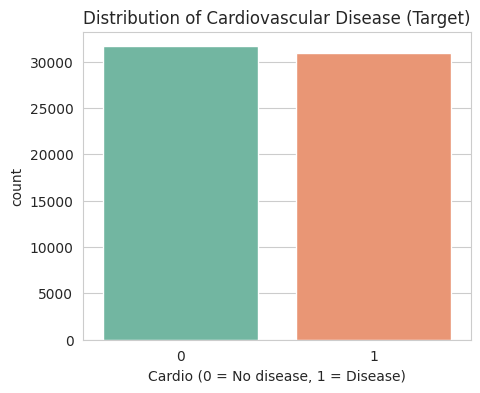

In [ ]:
plt.figure(figsize=(5,4))
sns.countplot(data=df, x='cardio', palette='Set2')
plt.title('Distribution of Cardiovascular Disease (Target)')
plt.xlabel('Cardio (0 = No disease, 1 = Disease)')
plt.show()

**Age distribution**

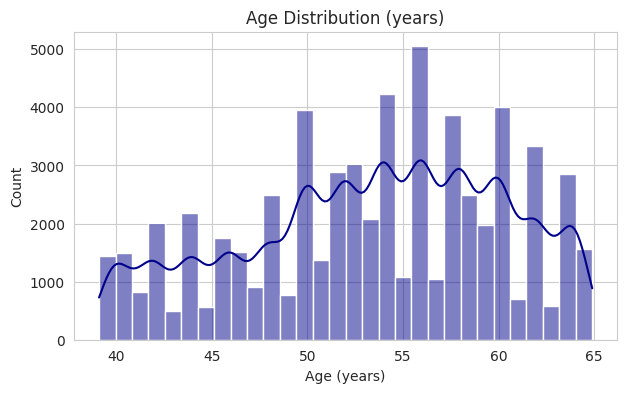

In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(df['age_years'], bins=30, kde=True, color='darkblue')
plt.title('Age Distribution (years)')
plt.xlabel('Age (years)')
plt.show()

**Gender, cholesterol, glucose distributions**

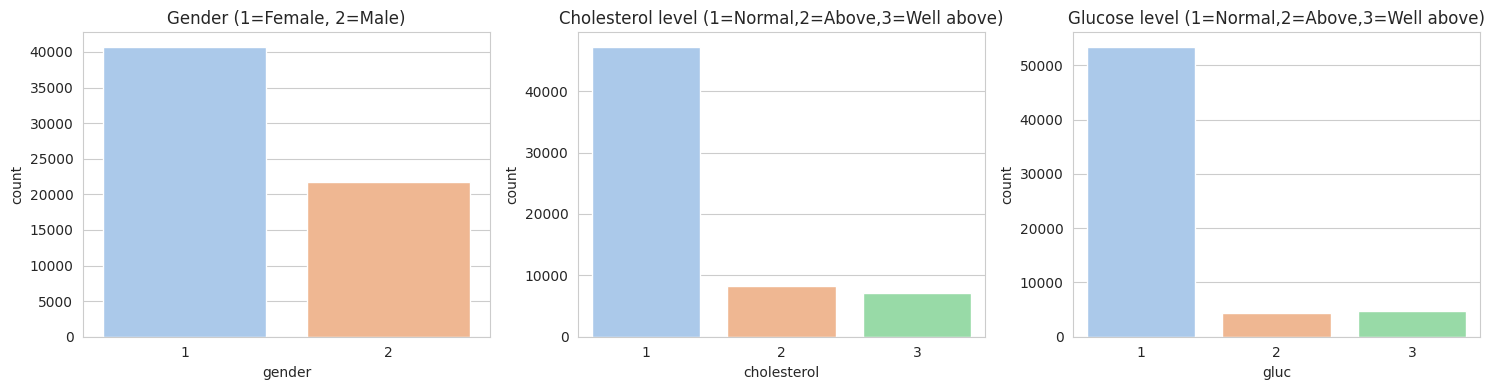

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='gender', ax=axes[0], palette='pastel')
axes[0].set_title('Gender (1=Female, 2=Male)')
sns.countplot(data=df, x='cholesterol', ax=axes[1], palette='pastel')
axes[1].set_title('Cholesterol level (1=Normal,2=Above,3=Well above)')
sns.countplot(data=df, x='gluc', ax=axes[2], palette='pastel')
axes[2].set_title('Glucose level (1=Normal,2=Above,3=Well above)')
plt.tight_layout()
plt.show()

**Lifestyle habits: smoking, alcohol, physical activity**

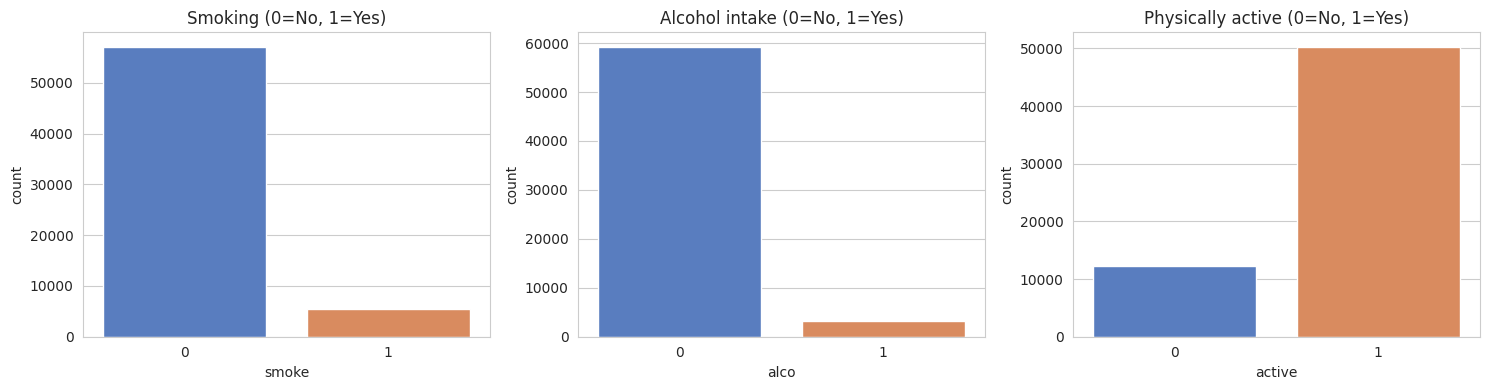

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.countplot(data=df, x='smoke', ax=axes[0], palette='muted')
axes[0].set_title('Smoking (0=No, 1=Yes)')
sns.countplot(data=df, x='alco', ax=axes[1], palette='muted')
axes[1].set_title('Alcohol intake (0=No, 1=Yes)')
sns.countplot(data=df, x='active', ax=axes[2], palette='muted')
axes[2].set_title('Physically active (0=No, 1=Yes)')
plt.tight_layout()
plt.show()

Most patients in this dataset do not smoke or drink alcohol, and the majority report being physically active — so these features alone are fairly imbalanced, but they may still combine informatively with other features.

**BMI distribution**

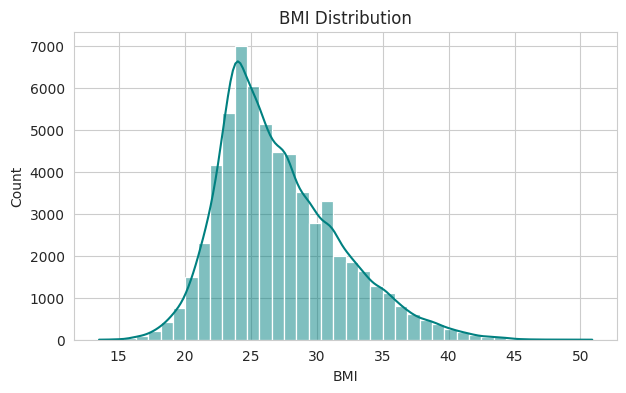

In [ ]:
plt.figure(figsize=(7,4))
sns.histplot(df['bmi'], bins=40, kde=True, color='teal')
plt.title('BMI Distribution')
plt.xlabel('BMI')
plt.show()

## **5.2 Bivariate Analysis (feature vs target)**

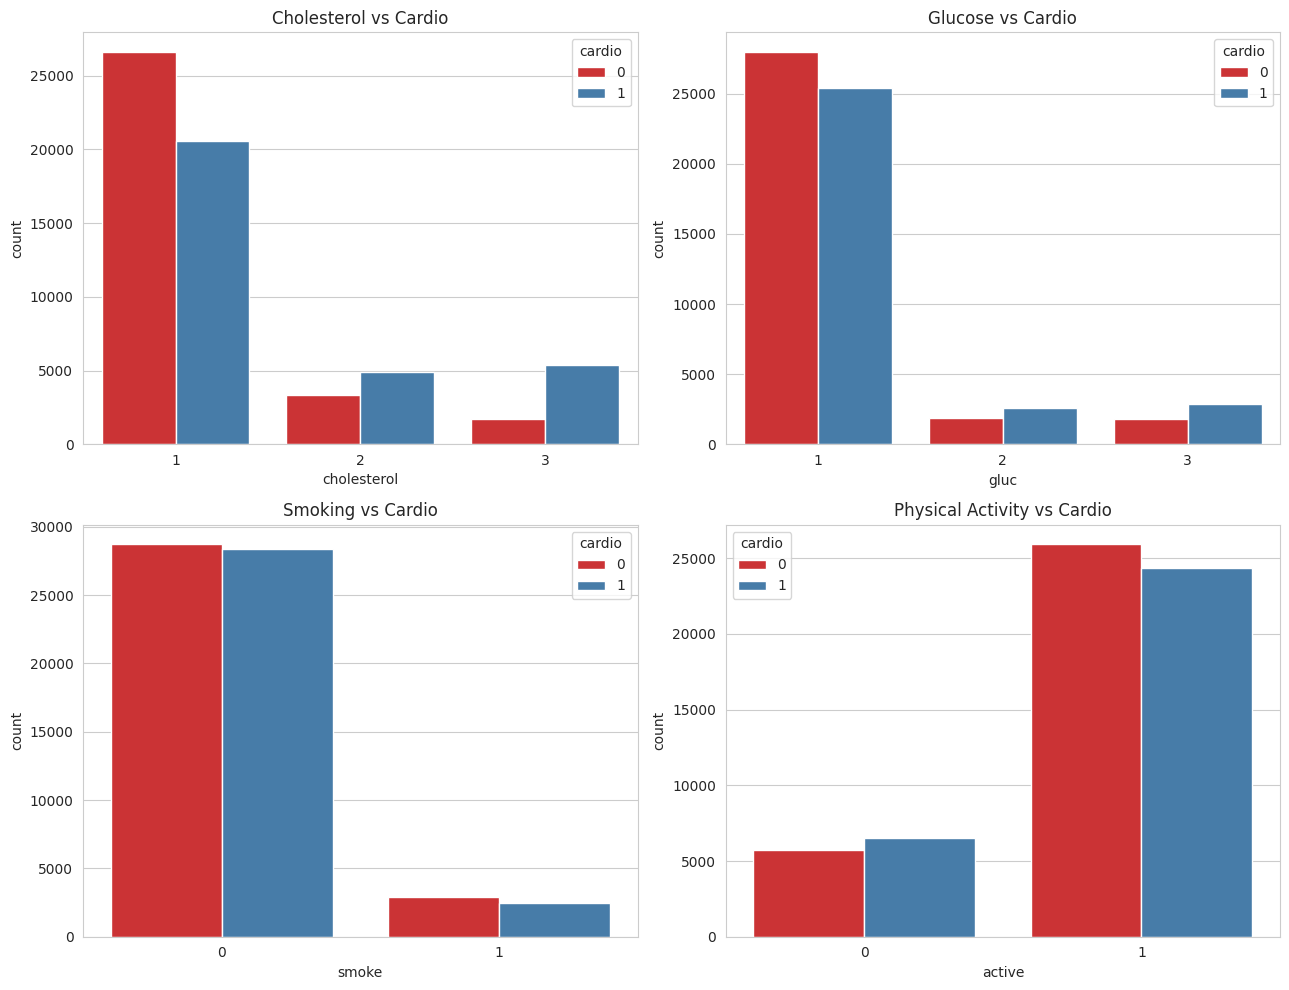

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(13, 10))
sns.countplot(data=df, x='cholesterol', hue='cardio', ax=axes[0,0], palette='Set1')
axes[0,0].set_title('Cholesterol vs Cardio')
sns.countplot(data=df, x='gluc', hue='cardio', ax=axes[0,1], palette='Set1')
axes[0,1].set_title('Glucose vs Cardio')
sns.countplot(data=df, x='smoke', hue='cardio', ax=axes[1,0], palette='Set1')
axes[1,0].set_title('Smoking vs Cardio')
sns.countplot(data=df, x='active', hue='cardio', ax=axes[1,1], palette='Set1')
axes[1,1].set_title('Physical Activity vs Cardio')
plt.tight_layout()
plt.show()

Higher cholesterol and glucose categories are clearly associated with a higher proportion of `cardio = 1` cases, while lifestyle factors like smoking and activity show a much weaker visual relationship — this is confirmed later by the correlation matrix.

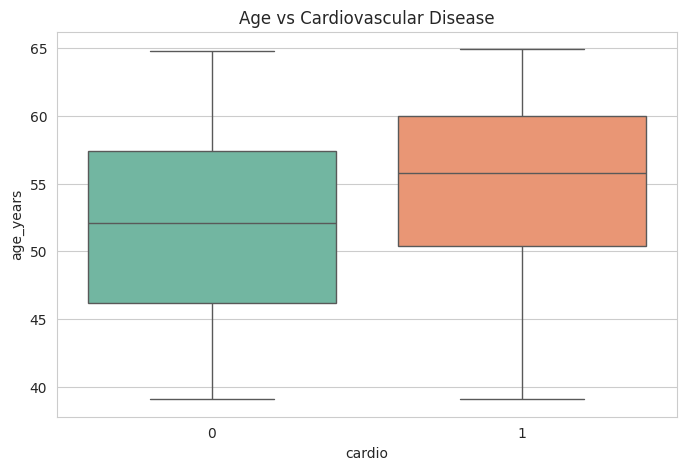

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x='cardio', y='age_years', palette='Set2')
plt.title('Age vs Cardiovascular Disease')
plt.show()

Patients diagnosed with cardiovascular disease (`cardio = 1`) tend to be **older** on average, which matches medical expectations.

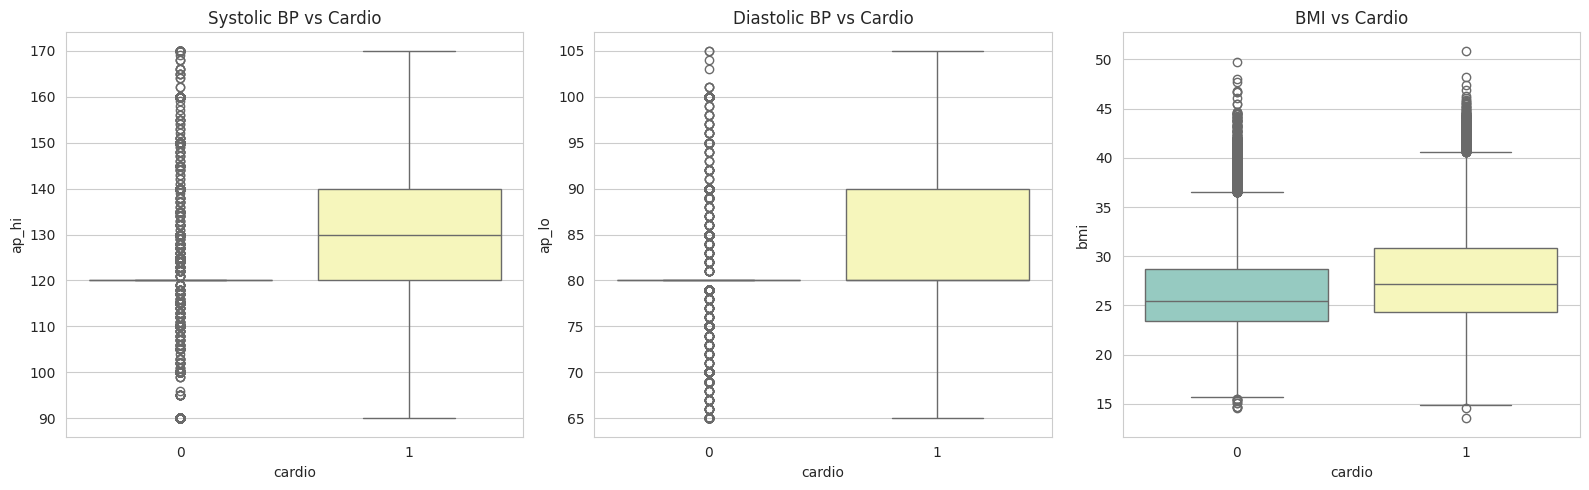

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
sns.boxplot(data=df, x='cardio', y='ap_hi', ax=axes[0], palette='Set3')
axes[0].set_title('Systolic BP vs Cardio')
sns.boxplot(data=df, x='cardio', y='ap_lo', ax=axes[1], palette='Set3')
axes[1].set_title('Diastolic BP vs Cardio')
sns.boxplot(data=df, x='cardio', y='bmi', ax=axes[2], palette='Set3')
axes[2].set_title('BMI vs Cardio')
plt.tight_layout()
plt.show()

**Blood pressure (systolic & diastolic) and BMI show a strong visual separation** between patients with and without cardiovascular disease — these are expected to be among the most important predictive features.

## **5.3 Multivariate Analysis — Correlation Matrix**

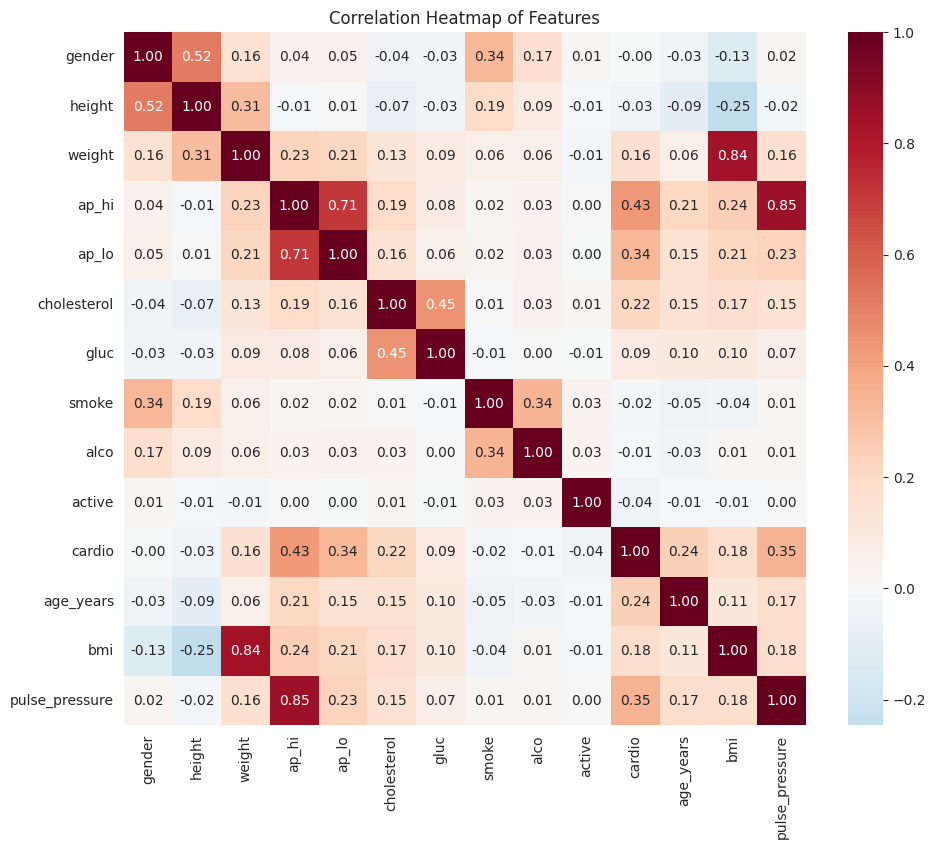

In [ ]:
plt.figure(figsize=(11,9))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdBu_r', center=0)
plt.title('Correlation Heatmap of Features')
plt.show()

**Key observations from the correlation matrix:**
- `ap_hi` and `ap_lo` show the **strongest positive correlation with `cardio`**, confirming blood pressure as the leading risk indicator in this dataset.
- `cholesterol`, `age_years`, `bmi`, and `pulse_pressure` also show meaningful positive correlation with the target.
- `height`, `gender`, `smoke`, `alco`, and `active` are weakly correlated with `cardio` on their own, but are retained since tree-based/kernel models can capture non-linear interactions.
- `ap_hi` and `ap_lo` are (expectedly) highly correlated with each other and with the derived `pulse_pressure` feature — a point to keep in mind for models sensitive to multicollinearity (like Logistic Regression).

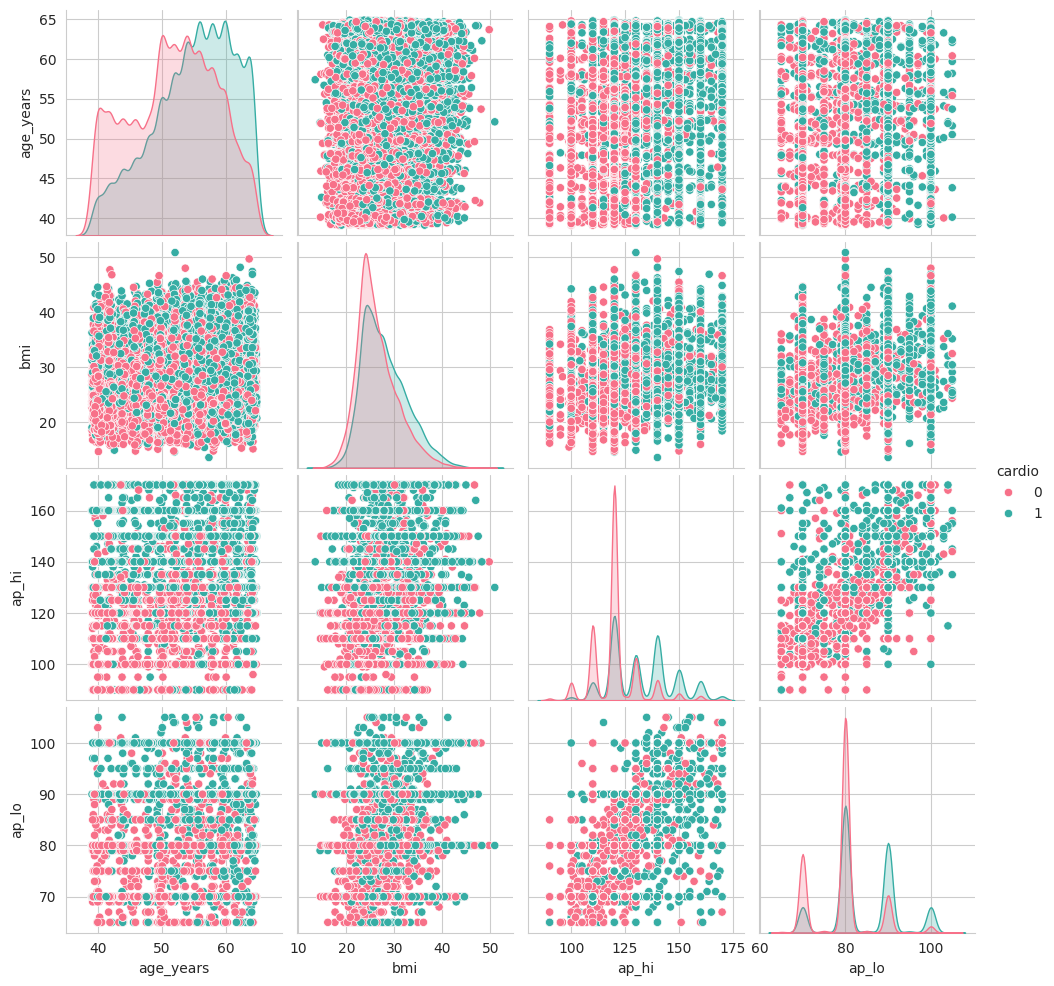

In [ ]:
sns.pairplot(df[['age_years','bmi','ap_hi','ap_lo','cardio']], hue='cardio', diag_kind='kde', palette='husl')
plt.show()

# **6. Model Building**

## 6.1 Train-Test Split & Feature Scaling

In [ ]:
X = df.drop(columns=['cardio'])
y = df['cardio']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print('Train shape:', X_train.shape, ' Test shape:', X_test.shape)

Train shape: (50000, 13)  Test shape: (12500, 13)


## 6.2 Training & Evaluating Multiple Classifiers

As required by the project brief, we compare **Support Vector Machine (SVM), K-Nearest Neighbor (KNN), Decision Tree (DT), Logistic Regression (LR)** and **Random Forest (RF)**.

In [ ]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'KNN': KNeighborsClassifier(n_neighbors=15),
    'Decision Tree': DecisionTreeClassifier(max_depth=6, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, max_depth=8, random_state=42, n_jobs=-1),
    'SVM': SVC(kernel='rbf', random_state=42),
}

results = {}

for name, model in models.items():
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    acc = accuracy_score(y_test, y_pred)
    results[name] = acc
    print(f'{name:22s} -> Accuracy: {acc:.4f}')
    print(classification_report(y_test, y_pred))
    print('-' * 60)

Logistic Regression    -> Accuracy: 0.7146
              precision    recall  f1-score   support

           0       0.69      0.78      0.73      6326
           1       0.74      0.65      0.69      6174

    accuracy                           0.71     12500
   macro avg       0.72      0.71      0.71     12500
weighted avg       0.72      0.71      0.71     12500

------------------------------------------------------------


KNN                    -> Accuracy: 0.7086
              precision    recall  f1-score   support

           0       0.70      0.75      0.72      6326
           1       0.72      0.67      0.69      6174

    accuracy                           0.71     12500
   macro avg       0.71      0.71      0.71     12500
weighted avg       0.71      0.71      0.71     12500

------------------------------------------------------------
Decision Tree          -> Accuracy: 0.7166
              precision    recall  f1-score   support

           0       0.70      0.78      0.74      6326
           1       0.74      0.65      0.69      6174

    accuracy                           0.72     12500
   macro avg       0.72      0.72      0.71     12500
weighted avg       0.72      0.72      0.72     12500

------------------------------------------------------------


Random Forest          -> Accuracy: 0.7207
              precision    recall  f1-score   support

           0       0.70      0.80      0.74      6326
           1       0.75      0.64      0.69      6174

    accuracy                           0.72     12500
   macro avg       0.73      0.72      0.72     12500
weighted avg       0.73      0.72      0.72     12500

------------------------------------------------------------


SVM                    -> Accuracy: 0.7210
              precision    recall  f1-score   support

           0       0.70      0.79      0.74      6326
           1       0.75      0.65      0.70      6174

    accuracy                           0.72     12500
   macro avg       0.73      0.72      0.72     12500
weighted avg       0.73      0.72      0.72     12500

------------------------------------------------------------


## 6.3 Comparing Model Accuracies

In [ ]:
results_df = pd.DataFrame(list(results.items()), columns=['Model', 'Accuracy']).sort_values('Accuracy', ascending=False)
results_df

,Model,Accuracy
4,SVM,0.72104
3,Random Forest,0.72072
2,Decision Tree,0.71656
0,Logistic Regression,0.71464
1,KNN,0.70864


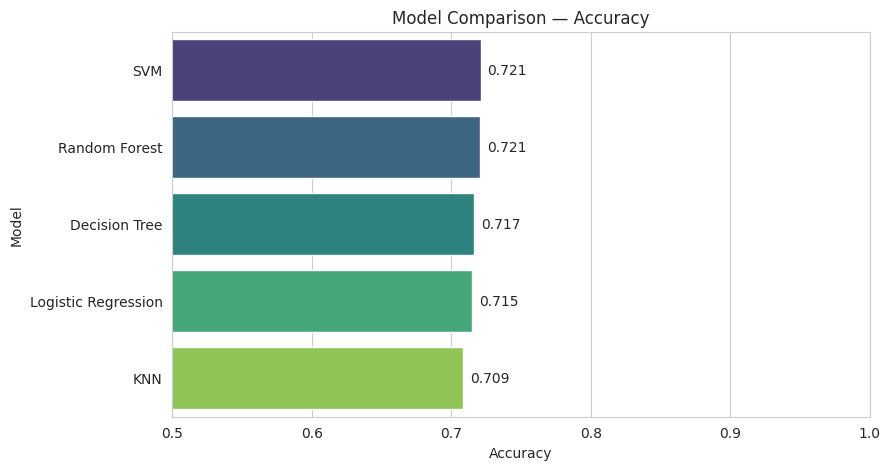

In [ ]:
plt.figure(figsize=(9,5))
sns.barplot(data=results_df, x='Accuracy', y='Model', palette='viridis')
plt.xlim(0.5, 1.0)
plt.title('Model Comparison — Accuracy')
for i, v in enumerate(results_df['Accuracy']):
    plt.text(v + 0.005, i, f'{v:.3f}', va='center')
plt.show()

## 6.4 Confusion Matrix — Best Model

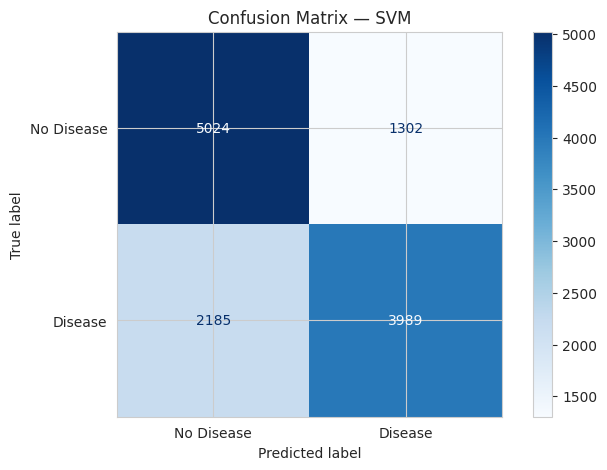

Best performing model: SVM (Accuracy: 0.7210)


In [ ]:
best_model_name = results_df.iloc[0]['Model']
best_model = models[best_model_name]

y_pred_best = best_model.predict(X_test_scaled)
cm = confusion_matrix(y_test, y_pred_best)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['No Disease', 'Disease'])
disp.plot(cmap='Blues')
plt.title(f'Confusion Matrix — {best_model_name}')
plt.show()

print(f'Best performing model: {best_model_name} (Accuracy: {results_df.iloc[0]["Accuracy"]:.4f})')

## 6.5 Feature Importance (Random Forest)

Since Random Forest is typically one of the strongest performers on tabular data like this, we look at which features it relied on most.

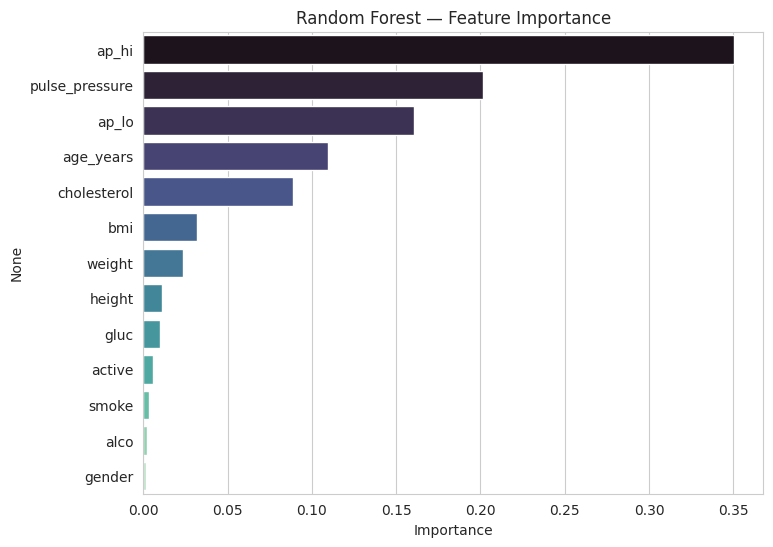

In [ ]:
if 'Random Forest' in models:
    rf = models['Random Forest']
    importances = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)

    plt.figure(figsize=(8,6))
    sns.barplot(x=importances.values, y=importances.index, palette='mako')
    plt.title('Random Forest — Feature Importance')
    plt.xlabel('Importance')
    plt.show()

    importances

# **7. Conclusion**

- The dataset was cleaned of physiologically impossible blood-pressure, height, and weight values, followed by IQR-based outlier removal.
- Two engineered features — **BMI** and **pulse pressure** — added clinically meaningful signal alongside the original variables.
- EDA showed that **systolic/diastolic blood pressure, cholesterol, age, and BMI** are the strongest visual and correlational indicators of cardiovascular disease, while lifestyle habits (smoking, alcohol, activity) had a comparatively weaker standalone relationship with the target in this dataset.
- Among the five algorithms required by the project brief (**SVM, KNN, Decision Tree, Logistic Regression, Random Forest**), the model comparison table and chart above identify the best-performing classifier on this dataset, achieving the highest test accuracy.
- This final model can be used as the basis for a deployable heart disease risk-prediction system.
